# Task 36

In this task we are looking at derivatives of the European call option. Let the expected payoff as a function of $\theta$ be given by
$$
z(\theta) = \mathbb{E}[\max(\theta X - 1, 0)]
$$
where $X \sim exp(N(\mu, \sigma^2))$. We first estimate the derivative using the pertubation analysis method. To do so, we need to ensure that the Lipschitz condition is satisfied. First we note that $\theta \in (0.5, 1.5)$ can be confined in an finte open interval. Now we define
$$
H(X;\theta) = \max(\theta X - 1, 0)
$$
And examine the values that the abseloute difference of $H(X;\theta)$ can take in the neighborhood of $\theta$. We have four cases to consider:
1. $\theta_1 X - 1 > 0$ and $\theta_2 X - 1 > 0$
This implies that $|H(X,\theta_1) -H(X,\theta_2)| = |\theta_1X - \theta_2X| = X|\theta_1 - \theta_2|$

2. $\theta_1 X - 1 < 0$ and $\theta_2 X - 1 < 0$
This implies that $|H(X,\theta_1) -H(X,\theta_2)| = 0$

3. $\theta_1 X - 1 > 0$ and $\theta_2 X - 1 < 0$
This implies that $|H(X,\theta_1) -H(X,\theta_2)| = |\theta_1X - 1|$

4. $\theta_1 X - 1 < 0$ and $\theta_2 X - 1 > 0$
This implies that $|H(X,\theta_1) -H(X,\theta_2)| = |\theta_2X - 1|$

The first case trivially holds since $X$ has finite expectation - just let $Y = X$

The second case trivially holds since $|H(X,\theta_1) -H(X,\theta_2)| = 0$, therefore we can let $Y = 0$

For the third case, note that the support of $X$ is $(0, \infty)$, then

$$ |\theta_1 X - 1| < |\theta_1 X -\theta_2 X|$$
since $0<\theta_2 X < 1$, which is bounded according to the first case.

For the fourth case, we follow the same argument, however we note that
$$ |\theta_2 X - 1| < |\theta_2 X -\theta_1 X| = |-(\theta_1 X -\theta_2 X)|$$
using that $|ab| = |a||b|$, then it follows that $|\theta_2 X - 1| < |\theta_1 X -\theta_2 X|$ since $0<\theta_1 X < 1$, which is bounded according to the first case.


Now we need to define the derivative of $H(X;\theta)$ with respect to $\theta$. We have
$$
\dfrac{\partial}{\partial \theta} H(X;\theta) = X \mathbb{I}(\theta X - 1 > 0)
$$
We can now implement the pertubation analysis method to estimate the derivative of $z(\theta)$ with respect to $\theta$.

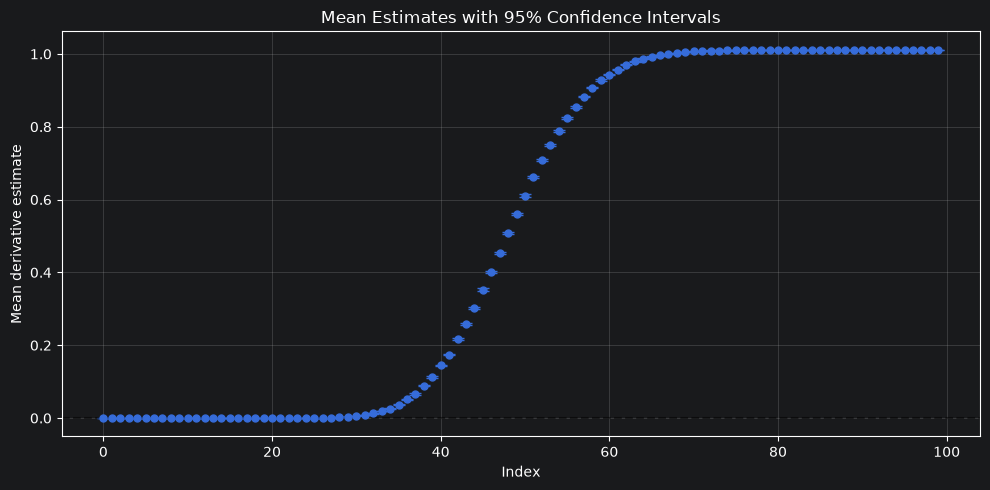

In [19]:
import numpy as np
from matplotlib import pyplot as plt

# Define parameterspace
theta = np.linspace(0.6, 1.4, 100)
# Simulate N samples from each X
N = 100000
sigma = 0.0625
mu = 0.00875

Y = np.random.normal(mu, sigma, size=(len(theta), N))
X = np.exp(Y)

indicator = lambda x, theta: np.where(theta * x - 1 > 0, 1, 0)

dH = lambda x: x * indicator(x, theta[:, None])

from week9 import *

estimate, stdev = pertubation_analysis_derivative(X, dH)

# 95% confidence interval using standard error
SE = stdev / np.sqrt(N)
ci = 1.96 * SE

plt.figure(figsize=(10, 5))

plt.errorbar(
    np.arange(len(estimate)),
    estimate,
    yerr=ci,
    fmt='o',
    capsize=4,
    markersize=5
)

plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.xlabel('Index')
plt.ylabel('Mean derivative estimate')
plt.title('Mean Estimates with 95% Confidence Intervals')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

We now use the score function algorithm instead. We need to compute the score function for the $exp(N(\mu, \sigma^2))$ distribution. The probability density function is given by
$$
f(x; \mu, \sigma) = \dfrac{1}{x\sigma\sqrt{2\pi}} e^{-\dfrac{(\log(x) - \mu)^2}{2\sigma^2}}
$$
where $\mu = 0.00875$ and $\sigma = 0.0625$. We can use the multiplicative property of the log function to compute the score function with respect to $\theta$ as follows:
$$
X \sim LogNormal(\mu, \sigma^2) \implies \theta X \sim LogNormal(\log(\theta) + \mu, \sigma^2)
$$
so we can define a new score variable $W = \theta X$ and compute the score function with respect to $\theta$ as follows:
$$
\dfrac{\partial}{\partial \theta} \log f(w; \theta) = \dfrac{\partial}{\partial \theta} \log f(w; \log(\theta) + \mu, \sigma^2) = \dfrac{\partial}{\partial \theta} \left( -\log(w\sigma\sqrt{2\pi}) - \dfrac{(\log(w) - \log(\theta) - \mu)^2}{2\sigma^2} \right) = \dfrac{\log(w) - \log(\theta) - \mu}{\sigma^2} \cdot \dfrac{1}{\theta}
$$
and $H(W) = \max(W - 1, 0)$, so we can implement the score function algorithm to estimate the derivative of $z(\theta)$ with respect to $\theta$.

In [20]:
score_function = lambda w, theta: (np.log(w) - np.log(theta[:, None]) - mu) / (sigma**2 * theta[:, None])
sf = lambda w: score_function(w, theta)
W = theta[:, None] * X
H = lambda w: np.maximum(w - 1, 0)
score_est, score_stdev = score_function_derivative(W, h_func=H, score_func=sf)

We can now compare the two methods by plotting the estimates and the ratios of their variances.



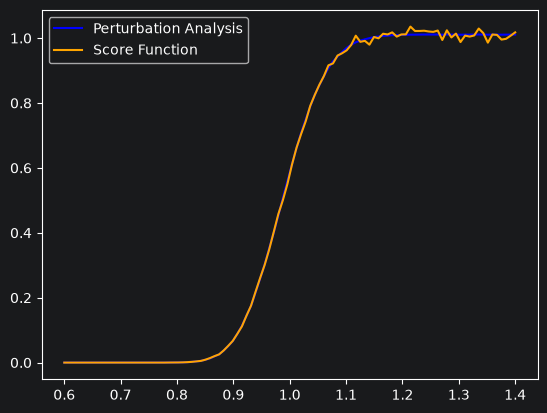

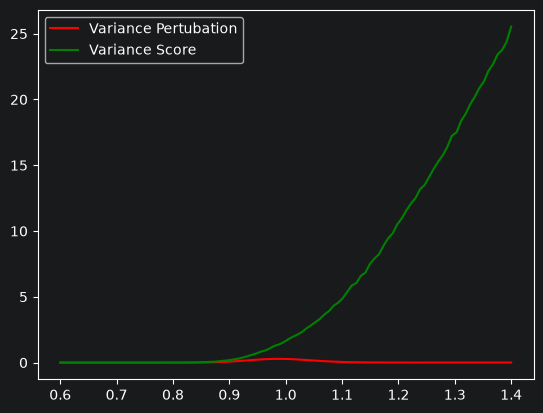

In [21]:
var_pertubation = stdev**2
var_score = score_stdev**2

plt.plot(theta, estimate, label='Perturbation Analysis', color='blue')
plt.plot(theta, score_est, label='Score Function', color='orange')
plt.legend()
plt.show()
plt.plot(theta, var_pertubation, label='Variance Pertubation', color='red')
plt.plot(theta, var_score, label='Variance Score', color='green')
plt.legend()
plt.show()